In [1]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving archive.zip to archive.zip
User uploaded file "archive.zip" with length 2353238 bytes


In [2]:
import zipfile
import os

# Find the downloaded ZIP file
zip_files = [f for f in os.listdir('/content') if f.endswith('.zip')]

print("ZIP files found:", zip_files)

ZIP files found: ['archive.zip']


In [3]:
import zipfile

zip_path = '/content/' + zip_files[0]

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/pothole_dataset')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
import os

for root, dirs, files in os.walk('/content/pothole_dataset'):
    print(root, "->", len(files), "files")

/content/pothole_dataset -> 0 files
/content/pothole_dataset/Dataset -> 0 files
/content/pothole_dataset/Dataset/train -> 0 files
/content/pothole_dataset/Dataset/train/Pothole -> 864 files
/content/pothole_dataset/Dataset/train/Normal -> 293 files
/content/pothole_dataset/Dataset/test -> 136 files
/content/pothole_dataset/Dataset/val -> 0 files
/content/pothole_dataset/Dataset/val/Pothole -> 62 files
/content/pothole_dataset/Dataset/val/Normal -> 46 files


In [5]:
import os

dataset_path = "/content/pothole_dataset/Dataset"

train_path = os.path.join(dataset_path, "train")
val_path = os.path.join(dataset_path, "val")

# Count training images
for category in ["Pothole", "Normal"]:
    path = os.path.join(train_path, category)
    print(category, ":", len(os.listdir(path)))

# Count validation images
print("\nValidation data:")

for category in ["Pothole", "Normal"]:
    path = os.path.join(val_path, category)
    print(category, ":", len(os.listdir(path)))

Pothole : 864
Normal : 293

Validation data:
Pothole : 62
Normal : 46


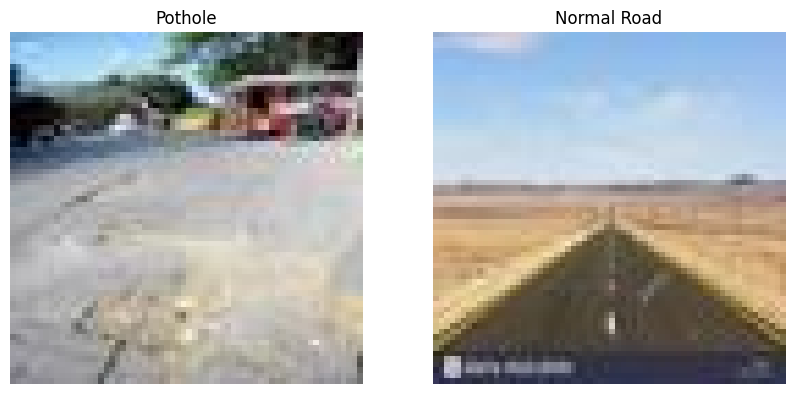

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import os

pothole_folder = train_path + "/Pothole"
normal_folder = train_path + "/Normal"

plt.figure(figsize=(10, 5))

# Show pothole image
img1 = Image.open(
    os.path.join(pothole_folder, os.listdir(pothole_folder)[0])
)

plt.subplot(1, 2, 1)
plt.imshow(img1)
plt.title("Pothole")
plt.axis("off")

# Show normal road image
img2 = Image.open(
    os.path.join(normal_folder, os.listdir(normal_folder)[0])
)

plt.subplot(1, 2, 2)
plt.imshow(img2)
plt.title("Normal Road")
plt.axis("off")

plt.show()

Pothole image size: (64, 64)
Normal image size: (64, 64)


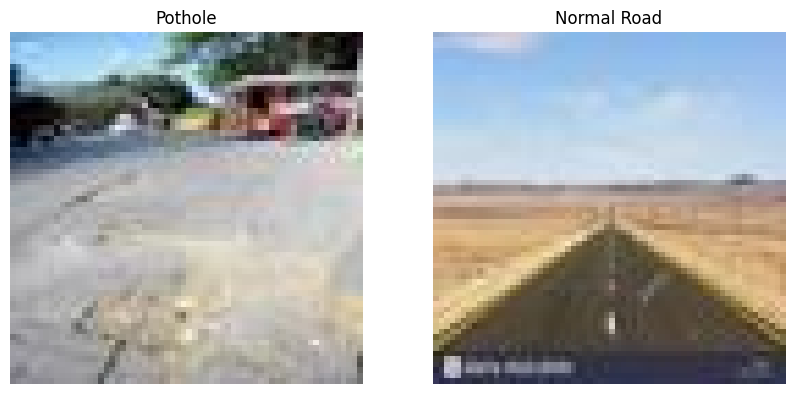

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
import os

pothole_folder = train_path + "/Pothole"
normal_folder = train_path + "/Normal"

# Get one image from each folder
pothole_image = os.listdir(pothole_folder)[0]
normal_image = os.listdir(normal_folder)[0]

img1 = Image.open(os.path.join(pothole_folder, pothole_image))
img2 = Image.open(os.path.join(normal_folder, normal_image))

print("Pothole image size:", img1.size)
print("Normal image size:", img2.size)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1)
plt.title("Pothole")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2)
plt.title("Normal Road")
plt.axis("off")

plt.show()

In [8]:
import numpy as np
from PIL import Image
import os

def load_images(folder):
    images = []
    labels = []

    categories = ["Pothole", "Normal"]

    for label, category in enumerate(categories):
        category_path = os.path.join(folder, category)

        for filename in os.listdir(category_path):
            image_path = os.path.join(category_path, filename)

            try:
                img = Image.open(image_path).convert("RGB")
                img = img.resize((64, 64))

                img_array = np.array(img) / 255.0

                images.append(img_array)
                labels.append(label)

            except Exception as e:
                print("Skipped:", filename, e)

    return np.array(images), np.array(labels)


X_train, y_train = load_images(train_path)
X_val, y_val = load_images(val_path)

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Validation data shape:", X_val.shape)
print("Validation labels shape:", y_val.shape)

Training data shape: (1157, 64, 64, 3)
Training labels shape: (1157,)
Validation data shape: (108, 64, 64, 3)
Validation labels shape: (108,)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Convert images into 1D arrays
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Training shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)

# Create the model
model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Train the model
model_lr.fit(X_train_flat, y_train)

# Make predictions
y_pred = model_lr.predict(X_val_flat)

# Evaluate the model
print("Accuracy:", accuracy_score(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_pred,
    target_names=["Pothole", "Normal"]
))

Training shape: (1157, 12288)
Validation shape: (108, 12288)
Accuracy: 0.8055555555555556

Classification Report:
              precision    recall  f1-score   support

     Pothole       0.79      0.90      0.84        62
      Normal       0.84      0.67      0.75        46

    accuracy                           0.81       108
   macro avg       0.81      0.79      0.79       108
weighted avg       0.81      0.81      0.80       108



In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
model_rf.fit(X_train_flat, y_train)

# Make predictions
y_pred_rf = model_rf.predict(X_val_flat)

# Evaluate
print("Random Forest Accuracy:",
      accuracy_score(y_val, y_pred_rf))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_rf,
    target_names=["Pothole", "Normal"]
))

Random Forest Accuracy: 0.7592592592592593

Classification Report:
              precision    recall  f1-score   support

     Pothole       0.71      0.97      0.82        62
      Normal       0.92      0.48      0.63        46

    accuracy                           0.76       108
   macro avg       0.82      0.72      0.73       108
weighted avg       0.80      0.76      0.74       108



In [11]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create model
model_gb = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=2,
    max_features="sqrt",
    random_state=42
)

# Train
model_gb.fit(X_train_flat, y_train)

# Predict
y_pred_gb = model_gb.predict(X_val_flat)

# Evaluate
print("Gradient Boosting Accuracy:",
      accuracy_score(y_val, y_pred_gb))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_gb,
    target_names=["Pothole", "Normal"]
))

Gradient Boosting Accuracy: 0.7592592592592593

Classification Report:
              precision    recall  f1-score   support

     Pothole       0.71      0.97      0.82        62
      Normal       0.92      0.48      0.63        46

    accuracy                           0.76       108
   macro avg       0.82      0.72      0.73       108
weighted avg       0.80      0.76      0.74       108



In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create baseline model
baseline = DummyClassifier(strategy="most_frequent")

# Train baseline
baseline.fit(X_train_flat, y_train)

# Predict validation data
y_pred_base = baseline.predict(X_val_flat)

# Evaluate
print("Baseline Accuracy:",
      accuracy_score(y_val, y_pred_base))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_base,
    target_names=["Pothole", "Normal"],
    zero_division=0
))

Baseline Accuracy: 0.5740740740740741

Classification Report:
              precision    recall  f1-score   support

     Pothole       0.57      1.00      0.73        62
      Normal       0.00      0.00      0.00        46

    accuracy                           0.57       108
   macro avg       0.29      0.50      0.36       108
weighted avg       0.33      0.57      0.42       108



In [13]:
test_path = dataset_path + "/test"

print("Test folder contents:")

for item in os.listdir(test_path):
    item_path = os.path.join(test_path, item)

    if os.path.isdir(item_path):
        print(item, "->", len(os.listdir(item_path)), "images")
    else:
        print(item)

Test folder contents:
pothole846.jpg
normal32.jpg
pothole841.jpg
normal25.jpg
normal7.jpg
normal59.jpg
pothole853.jpg
normal13.jpg
pothole886.jpg
pothole852.jpg
pothole868.jpg
normal34.jpg
normal70.jpg
normal68.jpg
pothole889.jpg
pothole848.jpg
pothole838.jpg
normal5.jpg
normal37.jpg
normal45.jpg
normal15.jpg
pothole857.jpg
pothole849.jpg
pothole854.jpg
normal28.jpg
pothole882.jpg
normal3.jpg
normal14.jpg
normal17.jpg
normal53.jpg
pothole885.jpg
normal22.jpg
pothole840.jpg
normal10.jpg
normal24.jpg
normal27.jpg
normal26.jpg
normal9.jpg
normal29.jpg
normal65.jpg
normal30.jpg
normal23.jpg
pothole896.jpg
pothole876.jpg
pothole864.jpg
pothole836.jpg
normal54.jpg
pothole880.jpg
normal51.jpg
pothole897.jpg
normal2.jpg
normal31.jpg
pothole881.jpg
normal40.jpg
pothole888.jpg
normal6.jpg
normal19.jpg
normal50.jpg
normal38.jpg
pothole898.jpg
pothole871.jpg
pothole850.jpg
normal69.jpg
pothole844.jpg
normal39.jpg
pothole891.jpg
normal33.jpg
pothole894.jpg
pothole865.jpg
normal12.jpg
normal60.jpg
n

In [14]:
import os
import numpy as np
from PIL import Image

X_test = []
y_test = []

for filename in os.listdir(test_path):

    image_path = os.path.join(test_path, filename)

    try:
        img = Image.open(image_path).convert("RGB")
        img = img.resize((64, 64))

        # Convert image into numbers
        img_array = np.array(img) / 255.0

        # Assign labels using filename
        if filename.lower().startswith("pothole"):
            label = 0
        elif filename.lower().startswith("normal"):
            label = 1
        else:
            continue

        X_test.append(img_array)
        y_test.append(label)

    except Exception as e:
        print("Skipped:", filename, e)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("Test images:", len(X_test))
print("Test labels:", len(y_test))
print("Pothole images:", np.sum(y_test == 0))
print("Normal images:", np.sum(y_test == 1))

Test images: 136
Test labels: 136
Pothole images: 65
Normal images: 71


In [15]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Flatten test images
X_test_flat = X_test.reshape(len(X_test), -1)

# Predict using Logistic Regression
y_test_pred = model_lr.predict(X_test_flat)

# Calculate accuracy
print("Final Test Accuracy:",
      accuracy_score(y_test, y_test_pred))

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Pothole", "Normal"]
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


Final Test Accuracy: 0.8823529411764706

Classification Report:
              precision    recall  f1-score   support

     Pothole       0.81      0.98      0.89        65
      Normal       0.98      0.79      0.88        71

    accuracy                           0.88       136
   macro avg       0.90      0.89      0.88       136
weighted avg       0.90      0.88      0.88       136


Confusion Matrix:
[[64  1]
 [15 56]]


In [16]:
from sklearn.metrics import accuracy_score

baseline_test_pred = baseline.predict(X_test_flat)

print("Baseline Test Accuracy:",
      accuracy_score(y_test, baseline_test_pred))

print("Logistic Regression Test Accuracy:",
      accuracy_score(y_test, y_test_pred))

Baseline Test Accuracy: 0.47794117647058826
Logistic Regression Test Accuracy: 0.8823529411764706


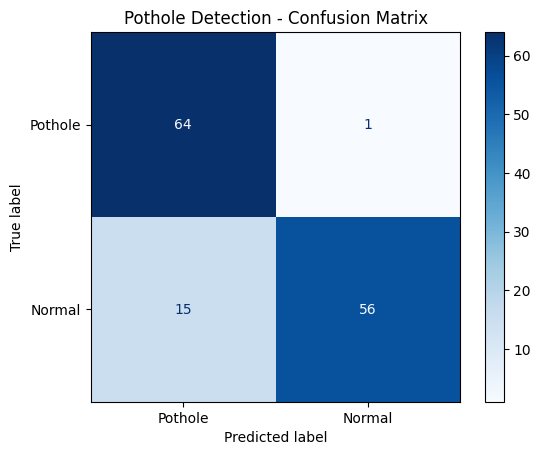

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix graph
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Pothole", "Normal"],
    cmap="Blues"
)

plt.title("Pothole Detection - Confusion Matrix")
plt.savefig("confusion_matrix.png")
plt.show()

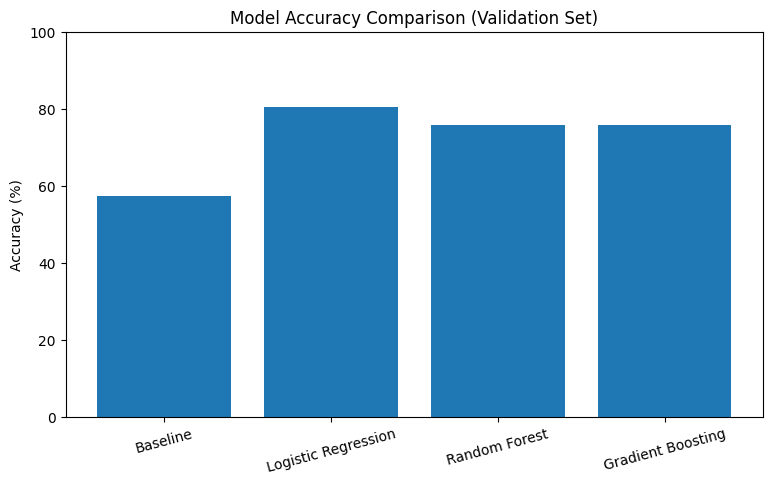

In [18]:
models = [
    "Baseline",
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting"
]

accuracies = [57.41, 80.56, 75.93, 75.93]

plt.figure(figsize=(9, 5))

plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison (Validation Set)")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.savefig("model_comparison.png")
plt.show()